# Early detection by attacked source — original Infiltration labels

Run this notebook in Google Colab, top to bottom. It extends the completed source and alert analyses; it does not train a model or rerun inference. It reads the probability caches and aligned window IDs created by `stgnn_spatial_ablation_colab.ipynb` and `temporal_operational_postanalysis_colab.ipynb`. If an input cache is missing, run those notebooks first.

The analysis asks whether ST-GNN's advantage appears in a source's first attack-containing windows or only after sustained activity. Every model uses its validation-selected checkpoint and threshold. Time is measured in nominal 30-second **flow-start** windows, so the curves are retrospective and do not estimate online alert latency. Labels are the original binary `Infilteration` labels; no attack stage or IP identity is inferred. Test 2 has already informed the hypothesis, so these results are exploratory.

## 1. Load and verify saved Test 2 predictions

The cell requires caches for all five original champions and both spatial ablations. It checks flow counts, labels, source IDs, the window-cache digests, and the published AP/F1 values. It never downloads or evaluates a model.

In [ ]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, f1_score

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
ABLATION_CACHE = DRIVE_ROOT / 'results_stgnn_spatial_ablation_v1' / 'diagnostic_test2_spatial'
OPERATIONAL_CACHE = DRIVE_ROOT / 'results_comparison' / 'temporal_operational_v1'
OUTPUT = DRIVE_ROOT / 'results_comparison' / 'early_source_dynamics_v1'

MODEL_CACHES = {
    'ST-GNN': ABLATION_CACHE / 'st_gnn_seed_42.npz',
    'ST Uniform': ABLATION_CACHE / 'st_uniform_seed_42.npz',
    'ST No Message': ABLATION_CACHE / 'st_no_message_seed_2024.npz',
    'Edge GRU': OPERATIONAL_CACHE / 'edge_gru_seed_99_test2.npz',
    'Simple MLP': OPERATIONAL_CACHE / 'SimpleMLP_BiasOn_seed_777_test2.npz',
    'E-GraphSAGE': OPERATIONAL_CACHE / 'EGraphSAGE_BiasOn_seed_99_test2.npz',
    'Static GNN': OPERATIONAL_CACHE / 'StaticGNN_BiasOn_robust_Identity_seed_42_test2.npz',
}
WINDOW_CACHE = OPERATIONAL_CACHE / 'window_ids_test2.npz'
missing = [str(path) for path in [*MODEL_CACHES.values(), WINDOW_CACHE] if not path.is_file()]
assert not missing, (
    'Missing verified caches. Run the spatial ablation and temporal operational '
    'post-analysis notebooks first:\n' + '\n'.join(missing)
)

EXPECTED = {
    'ST-GNN': (0.8384, 0.7576),
    'ST Uniform': (0.6883, 0.6256),
    'ST No Message': (0.6601, 0.7115),
    'Edge GRU': (0.7307, 0.6502),
    'Simple MLP': (0.3961, 0.4722),
    'E-GraphSAGE': (0.5050, 0.4950),
    'Static GNN': (0.3142, 0.2944),
}

predictions = {}
for name, path in MODEL_CACHES.items():
    with np.load(path, allow_pickle=False) as saved:
        labels_i = saved['labels'].astype(np.int8, copy=False)
        sources_i = saved['sources'].astype(np.int64, copy=False)
        probs_i = saved['probabilities'].astype(np.float32, copy=False)
        threshold_i = float(saved['threshold'])
        checkpoint_sha256 = str(saved['checkpoint_sha256'].item())
    assert len(labels_i) == len(sources_i) == len(probs_i) == 2_135_957, name
    assert int(labels_i.sum()) == 103_825, name
    assert np.isfinite(probs_i).all(), name
    assert 0.0 <= threshold_i <= 1.0, name
    assert len(checkpoint_sha256) == 64, name
    if predictions:
        np.testing.assert_array_equal(labels_i, predictions['ST-GNN']['labels'])
        np.testing.assert_array_equal(sources_i, predictions['ST-GNN']['sources'])
    decisions = probs_i > threshold_i  # Same strict operator as the audited evaluation.
    ap_i = average_precision_score(labels_i, probs_i)
    f1_i = f1_score(labels_i, decisions)
    expected_ap, expected_f1 = EXPECTED[name]
    assert np.isclose(ap_i, expected_ap, atol=0.0002), (name, 'AP', ap_i)
    assert np.isclose(f1_i, expected_f1, atol=0.0002), (name, 'F1', f1_i)
    predictions[name] = {
        'labels': labels_i, 'sources': sources_i, 'probs': probs_i,
        'threshold': threshold_i, 'checkpoint_sha256': checkpoint_sha256,
        'cache_path': str(path), 'AP': ap_i, 'F1': f1_i,
    }
    print(f'{name:13s} AP={ap_i:.4f} F1={f1_i:.4f}; cache verified')

labels = predictions['ST-GNN']['labels']
sources = predictions['ST-GNN']['sources']
with np.load(WINDOW_CACHE, allow_pickle=False) as saved:
    windows = saved['windows'].astype(np.int32, copy=False)
    saved_label_digest = str(saved['label_sha256'].item())
    saved_source_digest = str(saved['source_sha256'].item())
assert hashlib.sha256(labels.tobytes()).hexdigest() == saved_label_digest
assert hashlib.sha256(sources.tobytes()).hexdigest() == saved_source_digest
assert len(windows) == len(labels)
assert windows.min() >= 0 and windows.max() < 2_822
print('Aligned flows:', len(labels), '| attacked sources:', len(np.unique(sources[labels == 1])))


Mounted at /content/drive
ST-GNN        AP=0.8384 F1=0.7576; cache verified
ST Uniform    AP=0.6883 F1=0.6256; cache verified
ST No Message AP=0.6601 F1=0.7115; cache verified
Edge GRU      AP=0.7307 F1=0.6502; cache verified
Simple MLP    AP=0.3961 F1=0.4722; cache verified
E-GraphSAGE   AP=0.5050 F1=0.4950; cache verified
Static GNN    AP=0.3142 F1=0.2944; cache verified
Aligned flows: 2135957 | attacked sources: 380


## 2. Define source age and attack-window rank

For each attacked source, time zero is its first window containing at least one attack-labeled flow. Attack-window rank counts only windows in which that source has an attack-labeled flow; rank 1 is its first such window. A hit is an alert on an attack-labeled flow. All 380 attacked sources remain in the denominator, including those never detected.

An elapsed-time horizon of 5 minutes includes windows with offsets 0–9 from time zero; similarly 30 minutes includes offsets 0–59. A flow's position *within* one window is not treated as chronological, because the saved window cache does not contain an audited per-flow event time.

In [ ]:
positive_index = np.flatnonzero(labels == 1)
positive = pd.DataFrame({
    'flow_index': positive_index,
    'source_gid': sources[positive_index],
    'window': windows[positive_index],
})

source_support = positive.groupby('source_gid').agg(
    total_attack_flows=('flow_index', 'size'),
    first_attack_window=('window', 'min'),
    total_attack_windows=('window', 'nunique'),
).reset_index()
source_support['support_group'] = pd.cut(
    source_support['total_attack_flows'],
    bins=[0, 1, 9, 49, np.inf],
    labels=['1', '2-9', '10-49', '50+'],
).astype(str)

rank_lookup = (
    positive[['source_gid', 'window']]
    .drop_duplicates()
    .sort_values(['source_gid', 'window'])
    .reset_index(drop=True)
)
rank_lookup['attack_window_rank'] = rank_lookup.groupby('source_gid').cumcount() + 1
positive = positive.merge(
    rank_lookup, on=['source_gid', 'window'], how='left',
    sort=False, validate='many_to_one',
)
positive = positive.merge(
    source_support[['source_gid', 'first_attack_window', 'support_group']],
    on='source_gid', how='left', sort=False, validate='many_to_one',
)
positive = positive.sort_values('flow_index').reset_index(drop=True)
np.testing.assert_array_equal(positive['flow_index'].to_numpy(), positive_index)
positive['elapsed_windows'] = positive['window'] - positive['first_attack_window']
assert len(source_support) == 380
assert (positive['attack_window_rank'] >= 1).all()
assert (positive['elapsed_windows'] >= 0).all()
assert positive['support_group'].notna().all()
display(source_support.groupby('support_group', observed=True).agg(
    sources=('source_gid', 'size'),
    attack_flows=('total_attack_flows', 'sum'),
).reset_index())


,support_group,sources,attack_flows
0,1,25,25
1,10-49,31,703
2,2-9,304,847
3,50+,20,102250


## 3. Source-level early hits at fixed horizons

The next table has one row per model, source, and horizon. It reports attack flows available **within the defined retrospective horizon**, how many received a correct alert, and whether the source received at least one correct alert. Attack-flow recall weights high-volume sources; detected-source fraction gives each source equal weight. Both are reported.

No thresholds are selected from Test 2. Results for support groups and source 1195 are descriptive subgroup analyses.

In [ ]:
HORIZONS = [
    ('attack_windows', 1), ('attack_windows', 5), ('attack_windows', 20),
    ('elapsed_minutes', 5), ('elapsed_minutes', 30), ('elapsed_minutes', 120),
]

source_horizon_parts = []
first_hit_parts = []
positive_source = positive['source_gid'].to_numpy()
positive_window = positive['window'].to_numpy()
positive_rank = positive['attack_window_rank'].to_numpy()
positive_elapsed = positive['elapsed_windows'].to_numpy()
positive_flow_index = positive['flow_index'].to_numpy()

for model_name, record in predictions.items():
    hit = record['probs'][positive_flow_index] > record['threshold']
    hit_frame = positive.loc[hit, ['source_gid', 'window', 'attack_window_rank', 'elapsed_windows']]
    first_hit = (
        hit_frame.sort_values(['source_gid', 'window'])
        .drop_duplicates('source_gid')
        .rename(columns={
            'window': 'first_hit_window',
            'attack_window_rank': 'first_hit_attack_window_rank',
            'elapsed_windows': 'first_hit_elapsed_windows',
        })
    )
    first_hit = source_support.merge(
        first_hit, on='source_gid', how='left', validate='one_to_one',
    )
    first_hit['model'] = model_name
    first_hit['detected_ever'] = first_hit['first_hit_window'].notna()
    first_hit['first_hit_nominal_minutes'] = first_hit['first_hit_elapsed_windows'] * 0.5
    first_hit_parts.append(first_hit)

    for horizon_type, horizon_value in HORIZONS:
        within = (
            positive_rank <= horizon_value
            if horizon_type == 'attack_windows'
            else positive_elapsed < (horizon_value * 2)
        )
        included_sources = positive_source[within]
        included_hit = hit[within]
        included_windows = positive_window[within]
        grouped = (
            pd.DataFrame({
                'source_gid': included_sources,
                'window': included_windows,
                'hit': included_hit,
            })
            .groupby('source_gid')
            .agg(
                attack_flows=('hit', 'size'),
                true_positive_flows=('hit', 'sum'),
                attack_windows=('window', 'nunique'),
            )
            .reset_index()
        )
        one_horizon = source_support.merge(
            grouped, on='source_gid', how='left', validate='one_to_one',
        )
        assert one_horizon['attack_flows'].notna().all()
        one_horizon['model'] = model_name
        one_horizon['horizon_type'] = horizon_type
        one_horizon['horizon_value'] = horizon_value
        one_horizon['detected'] = one_horizon['true_positive_flows'] > 0
        one_horizon['source_attack_flow_recall'] = (
            one_horizon['true_positive_flows'] / one_horizon['attack_flows']
        )
        source_horizon_parts.append(one_horizon)

source_horizon = pd.concat(source_horizon_parts, ignore_index=True)
source_first_hit = pd.concat(first_hit_parts, ignore_index=True)
assert len(source_horizon) == len(predictions) * len(HORIZONS) * 380
assert len(source_first_hit) == len(predictions) * 380
print('Source-horizon rows:', len(source_horizon))
print('Never-detected sources by model:')
display(source_first_hit.groupby('model')['detected_ever'].agg(
    detected='sum', attacked_sources='size',
).reset_index())


Source-horizon rows: 15960
Never-detected sources by model:


,model,detected,attacked_sources
0,E-GraphSAGE,58,380
1,Edge GRU,113,380
2,ST No Message,111,380
3,ST Uniform,188,380
4,ST-GNN,141,380
5,Simple MLP,49,380
6,Static GNN,31,380


## 4. Summaries and paired differences

The all-source and source-1195-excluded summaries use the same attacked-source denominator for every model. Support groups are defined by each source's **total** Test 2 attack count and are for diagnosis only. Paired rows compare the same sources under each model. The analysis reports differences and discordant-source counts without treating individual flows as independent statistical replicates.

In [ ]:
SUMMARY_SUBSETS = {
    'All attacked sources': lambda frame: np.ones(len(frame), dtype=bool),
    'Without source 1195': lambda frame: frame['source_gid'].to_numpy() != 1195,
}
for support in ['1', '2-9', '10-49', '50+']:
    SUMMARY_SUBSETS[f'Support {support}'] = (
        lambda frame, support=support:
        frame['support_group'].to_numpy() == support
    )

summary_rows = []
for (model_name, horizon_type, horizon_value), frame in source_horizon.groupby(
    ['model', 'horizon_type', 'horizon_value'], sort=False
):
    for subset_name, selector in SUMMARY_SUBSETS.items():
        part = frame.loc[selector(frame)]
        summary_rows.append({
            'subset': subset_name, 'model': model_name,
            'horizon_type': horizon_type, 'horizon_value': int(horizon_value),
            'attacked_sources': len(part),
            'detected_sources': int(part['detected'].sum()),
            'detected_source_fraction': part['detected'].mean(),
            'attack_flows_in_horizon': int(part['attack_flows'].sum()),
            'true_positive_flows': int(part['true_positive_flows'].sum()),
            'attack_flow_recall': (
                part['true_positive_flows'].sum() / part['attack_flows'].sum()
            ),
            'mean_source_attack_flow_recall': part['source_attack_flow_recall'].mean(),
        })
summary = pd.DataFrame(summary_rows)

pair_rows = []
for comparator in ['Edge GRU', 'ST No Message', 'ST Uniform']:
    left = source_horizon[source_horizon['model'] == 'ST-GNN']
    right = source_horizon[source_horizon['model'] == comparator]
    paired = left.merge(
        right[['source_gid', 'horizon_type', 'horizon_value', 'detected',
               'true_positive_flows', 'attack_flows']],
        on=['source_gid', 'horizon_type', 'horizon_value'],
        suffixes=('_st', '_other'), validate='one_to_one',
    )
    assert (paired['attack_flows_st'] == paired['attack_flows_other']).all()
    for (horizon_type, horizon_value), frame in paired.groupby(
        ['horizon_type', 'horizon_value'], sort=False
    ):
        for subset_name in ['All attacked sources', 'Without source 1195']:
            part = frame if subset_name == 'All attacked sources' else frame[frame['source_gid'] != 1195]
            st_hit = part['detected_st'].to_numpy(dtype=bool)
            other_hit = part['detected_other'].to_numpy(dtype=bool)
            pair_rows.append({
                'subset': subset_name, 'comparator': comparator,
                'horizon_type': horizon_type, 'horizon_value': int(horizon_value),
                'attacked_sources': len(part),
                'both_detected': int((st_hit & other_hit).sum()),
                'ST_only': int((st_hit & ~other_hit).sum()),
                'comparator_only': int((~st_hit & other_hit).sum()),
                'neither_detected': int((~st_hit & ~other_hit).sum()),
                'detected_source_fraction_difference_ST_minus_comparator': (
                    st_hit.mean() - other_hit.mean()
                ),
                'attack_flow_recall_difference_ST_minus_comparator': (
                    part['true_positive_flows_st'].sum() / part['attack_flows_st'].sum()
                    - part['true_positive_flows_other'].sum() / part['attack_flows_other'].sum()
                ),
            })
pairs = pd.DataFrame(pair_rows)

print('Early detection summary: all sources and source 1195 excluded')
display(summary[
    summary['subset'].isin(['All attacked sources', 'Without source 1195'])
    & summary['model'].isin(['ST-GNN', 'Edge GRU', 'ST No Message', 'ST Uniform'])
].sort_values(['horizon_type', 'horizon_value', 'subset', 'model']).round(4))
print('Paired differences: ST-GNN versus Edge GRU and ST No Message')
display(pairs[pairs['comparator'].isin(['Edge GRU', 'ST No Message'])]
        .sort_values(['horizon_type', 'horizon_value', 'subset', 'comparator']).round(4))


Early detection summary: all sources and source 1195 excluded


,subset,model,horizon_type,horizon_value,attacked_sources,detected_sources,detected_source_fraction,attack_flows_in_horizon,true_positive_flows,attack_flow_recall,mean_source_attack_flow_recall
108,All attacked sources,Edge GRU,attack_windows,1,380,96,0.2526,1052,231,0.2196,0.2311
72,All attacked sources,ST No Message,attack_windows,1,380,69,0.1816,1052,174,0.1654,0.1768
36,All attacked sources,ST Uniform,attack_windows,1,380,153,0.4026,1052,363,0.3451,0.4013
0,All attacked sources,ST-GNN,attack_windows,1,380,100,0.2632,1052,240,0.2281,0.2570
109,Without source 1195,Edge GRU,attack_windows,1,379,96,0.2533,1035,231,0.2232,0.2317
73,Without source 1195,ST No Message,attack_windows,1,379,69,0.1821,1035,174,0.1681,0.1772
37,Without source 1195,ST Uniform,attack_windows,1,379,153,0.4037,1035,363,0.3507,0.4024
1,Without source 1195,ST-GNN,attack_windows,1,379,100,0.2639,1035,240,0.2319,0.2577
114,All attacked sources,Edge GRU,attack_windows,5,380,111,0.2921,1887,656,0.3476,0.2270
78,All attacked sources,ST No Message,attack_windows,5,380,101,0.2658,1887,617,0.3270,0.2009


Paired differences: ST-GNN versus Edge GRU and ST No Message


,subset,comparator,horizon_type,horizon_value,attacked_sources,both_detected,ST_only,comparator_only,neither_detected,detected_source_fraction_difference_ST_minus_comparator,attack_flow_recall_difference_ST_minus_comparator
0,All attacked sources,Edge GRU,attack_windows,1,380,50,50,46,234,0.0105,0.0086
12,All attacked sources,ST No Message,attack_windows,1,380,33,67,36,244,0.0816,0.0627
1,Without source 1195,Edge GRU,attack_windows,1,379,50,50,46,233,0.0106,0.0087
13,Without source 1195,ST No Message,attack_windows,1,379,33,67,36,243,0.0818,0.0638
2,All attacked sources,Edge GRU,attack_windows,5,380,78,56,33,213,0.0605,0.0069
14,All attacked sources,ST No Message,attack_windows,5,380,68,66,33,213,0.0868,0.0276
3,Without source 1195,Edge GRU,attack_windows,5,379,78,56,33,212,0.0607,0.0070
15,Without source 1195,ST No Message,attack_windows,5,379,68,66,33,212,0.0871,0.0279
4,All attacked sources,Edge GRU,attack_windows,20,380,82,57,30,211,0.0711,0.0541
16,All attacked sources,ST No Message,attack_windows,20,380,77,62,32,209,0.0789,0.0462


In [ ]:
models = ['ST-GNN', 'ST Uniform', 'Edge GRU', 'ST No Message']
subsets = ['All attacked sources', 'Without source 1195']

horizons = [
    ('attack_windows', 1, 'First attack window'),
    ('elapsed_minutes', 5, '5 min'),
    ('elapsed_minutes', 30, '30 min'),
    ('elapsed_minutes', 120, '120 min'),
]

lookup = {
    (row['subset'], row['model'], row['horizon_type'], int(row['horizon_value'])): row
    for _, row in summary.iterrows()
}

rows = []
for subset in subsets:
    for model in models:
        result = {'Subset': subset, 'Model': model}

        for horizon_type, horizon_value, label in horizons:
            item = lookup[(subset, model, horizon_type, horizon_value)]
            detected = int(item['detected_sources'])
            total = int(item['attacked_sources'])
            result[label] = f'{detected}/{total} ({detected / total:.1%})'

        item_120 = lookup[(subset, model, 'elapsed_minutes', 120)]
        result['Attack-flow recall at 120 min'] = (
            f"{item_120['attack_flow_recall']:.1%}"
        )
        rows.append(result)

compact_table = pd.DataFrame(rows).set_index(['Subset', 'Model'])
display(compact_table)

compact_table.to_csv(OUTPUT / 'compact_early_detection_table.csv')


First attack window            5 min  \
Subset               Model                                                
All attacked sources ST-GNN            100/380 (26.3%)  110/380 (28.9%)   
                     ST Uniform        153/380 (40.3%)  167/380 (43.9%)   
                     Edge GRU           96/380 (25.3%)  102/380 (26.8%)   
                     ST No Message      69/380 (18.2%)   82/380 (21.6%)   
Without source 1195  ST-GNN            100/379 (26.4%)  110/379 (29.0%)   
                     ST Uniform        153/379 (40.4%)  167/379 (44.1%)   
                     Edge GRU           96/379 (25.3%)  102/379 (26.9%)   
                     ST No Message      69/379 (18.2%)   82/379 (21.6%)   

                                             30 min          120 min  \
Subset               Model                                             
All attacked sources ST-GNN         121/380 (31.8%)  127/380 (33.4%)   
                     ST Uniform     174/380 (45.8%)  178/380 (46.8%)   
                     Edge GRU       108/380 (28.4%)  112/380 (29.5%)   
                     ST No Message   91/380 (23.9%)   96/380 (25.3%)   
Without source 1195  ST-GNN         121/379 (31.9%)  126/379 (33.2%)   
                     ST Uniform     174/379 (45.9%)  177/379 (46.7%)   
                     Edge GRU       108/379 (28.5%)  111/379 (29.3%)   
                     ST No Message   91/379 (24.0%)   96/379 (25.3%)   

                                   Attack-flow recall at 120 min  
Subset               Model                                        
All attacked sources ST-GNN                                81.7%  
                     ST Uniform                            69.6%  
                     Edge GRU                              62.8%  
                     ST No Message                         62.1%  
Without source 1195  ST-GNN                                83.8%  
                     ST Uniform                            89.9%  
                     Edge GRU                              79.7%  
                     ST No Message                         82.2%

## 5. Cumulative source detection

Each curve shows the fraction of **all** attacked sources with at least one true positive by the indicated attack-window rank or nominal elapsed time. Never-detected sources remain in the denominator. The lower row excludes source 1195 from both numerator and denominator. These are flow-start-window curves, not online latency curves.

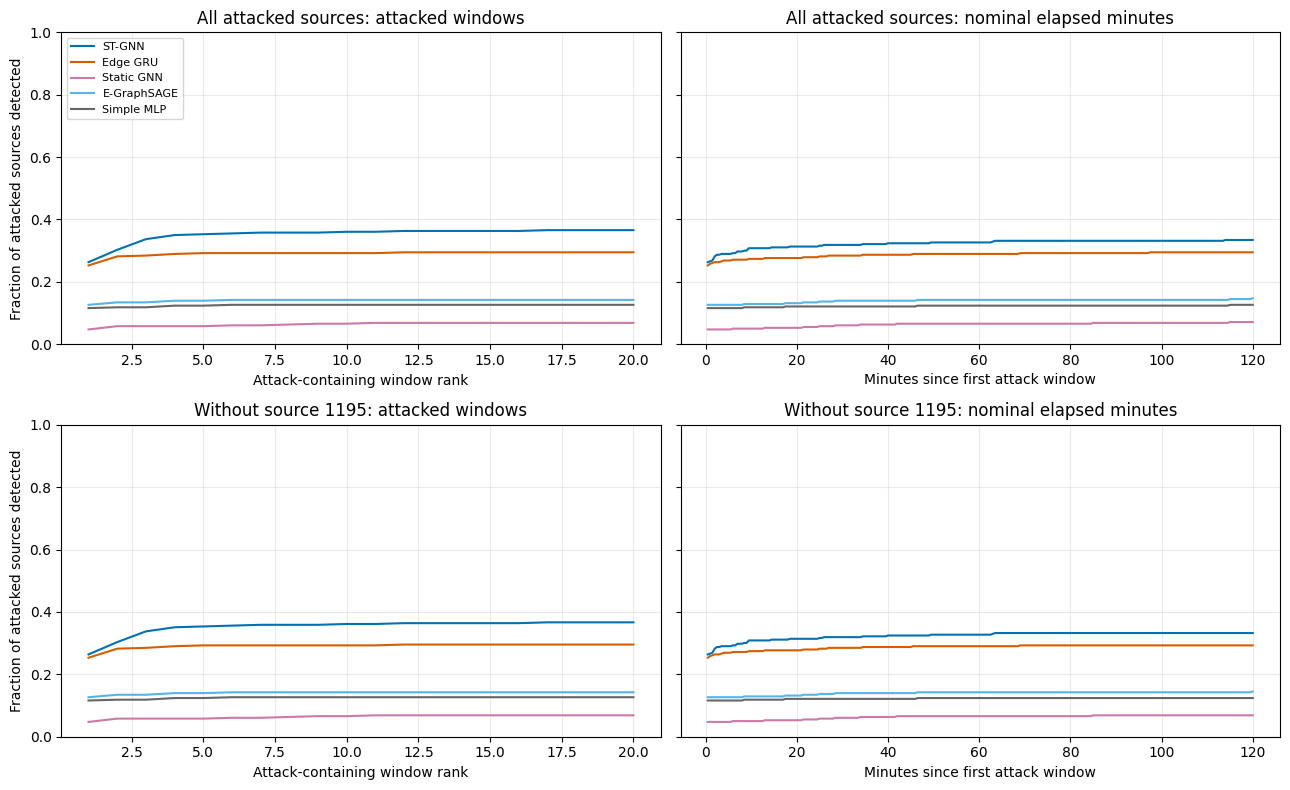

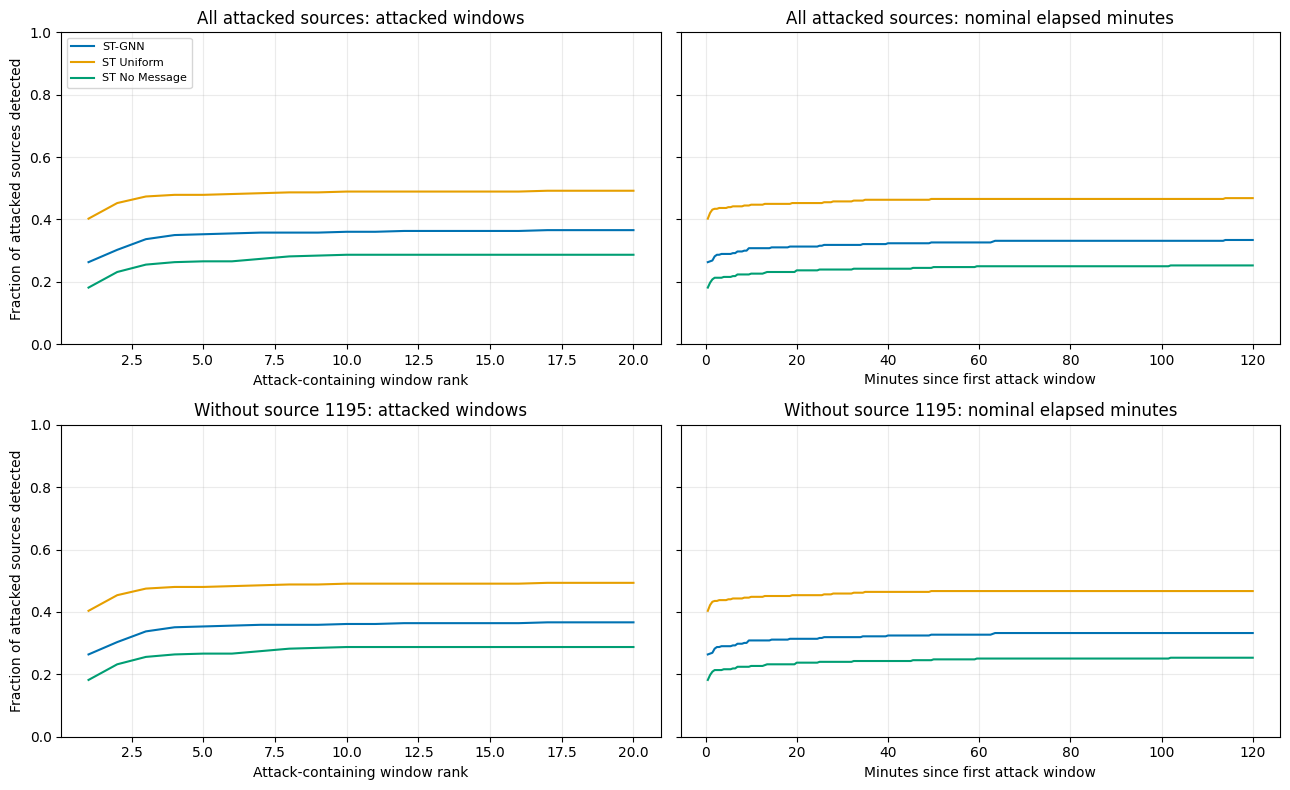

In [ ]:
OUTPUT.mkdir(parents=True, exist_ok=True)
PLOT_GROUPS = {
    'early_source_baselines': ['ST-GNN', 'Edge GRU', 'Static GNN', 'E-GraphSAGE', 'Simple MLP'],
    'early_source_ablations': ['ST-GNN', 'ST Uniform', 'ST No Message'],
}
COLORS = {
    'ST-GNN': '#0072B2', 'Edge GRU': '#D55E00',
    'ST Uniform': '#E69F00', 'ST No Message': '#009E73',
    'Static GNN': '#CC79A7', 'E-GraphSAGE': '#56B4E9',
    'Simple MLP': '#666666',
}
rank_grid = np.arange(1, 21)
minute_grid = np.arange(1, 241) * 0.5

for filename, model_names in PLOT_GROUPS.items():
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
    for row, exclude_main in enumerate([False, True]):
        title_prefix = 'Without source 1195' if exclude_main else 'All attacked sources'
        for name in model_names:
            frame = source_first_hit[source_first_hit['model'] == name]
            if exclude_main:
                frame = frame[frame['source_gid'] != 1195]
            denominator = len(frame)
            ranks = frame['first_hit_attack_window_rank'].to_numpy()
            times = frame['first_hit_nominal_minutes'].to_numpy()
            rank_coverage = np.array([np.count_nonzero(ranks <= k) / denominator for k in rank_grid])
            time_coverage = np.array([np.count_nonzero(times < t) / denominator for t in minute_grid])
            axes[row, 0].plot(rank_grid, rank_coverage, label=name, color=COLORS[name])
            axes[row, 1].plot(minute_grid, time_coverage, label=name, color=COLORS[name])
        axes[row, 0].set_title(f'{title_prefix}: attacked windows')
        axes[row, 1].set_title(f'{title_prefix}: nominal elapsed minutes')
        axes[row, 0].set_xlabel('Attack-containing window rank')
        axes[row, 1].set_xlabel('Minutes since first attack window')
        axes[row, 0].set_ylabel('Fraction of attacked sources detected')
        for ax in axes[row]:
            ax.set_ylim(0, 1)
            ax.grid(alpha=0.25)
    axes[0, 0].legend(loc='upper left', fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{filename}.pdf', bbox_inches='tight')
    fig.savefig(OUTPUT / f'{filename}.png', dpi=240, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 6. Save aligned results and provenance

Outputs are written to a new Drive folder. Existing prediction caches and original result tables are read only. The manifest records input paths, checkpoint hashes embedded in those caches, thresholds, and the exact window conventions. The notebook cannot independently validate a checkpoint file that is absent from Drive; the upstream notebooks perform that check.

In [ ]:
attack_flows = positive.copy()
attack_flows['label'] = 1
for name, record in predictions.items():
    slug = name.lower().replace('-', '_').replace(' ', '_')
    scores = record['probs'][positive_flow_index]
    attack_flows[f'{slug}_score'] = scores
    attack_flows[f'{slug}_hit'] = (scores > record['threshold']).astype(np.int8)
attack_flows.to_csv(OUTPUT / 'attack_flow_scores_and_hits.csv', index=False)
source_support.to_csv(OUTPUT / 'source_support.csv', index=False)
source_first_hit.to_csv(OUTPUT / 'source_first_hit.csv', index=False)
source_horizon.to_csv(OUTPUT / 'source_horizon_metrics.csv', index=False)
summary.to_csv(OUTPUT / 'early_detection_summary.csv', index=False)
pairs.to_csv(OUTPUT / 'early_detection_paired_differences.csv', index=False)

manifest = {
    'analysis': 'Early detection by attacked source, exploratory Test 2',
    'labels': 'original Infilteration binary labels',
    'window_seconds': 30,
    'time_axis': 'flow-start windows; retrospective nominal time, not online latency',
    'horizons': [{'type': kind, 'value': value} for kind, value in HORIZONS],
    'elapsed_horizon_rule': 'elapsed_windows < 2 * elapsed_minutes',
    'attack_window_rule': 'attack_window_rank <= requested rank',
    'alert_rule': 'probability > validation-selected threshold',
    'positive_flows': int(labels.sum()),
    'total_flows': len(labels),
    'attacked_sources': len(source_support),
    'source_1195_is_day_local_id': True,
    'attack_flow_table': 'attack_flow_scores_and_hits.csv',
    'window_cache': str(WINDOW_CACHE),
    'label_sha256': saved_label_digest,
    'source_sha256': saved_source_digest,
    'models': {
        name: {
            'cache_path': record['cache_path'],
            'checkpoint_sha256': record['checkpoint_sha256'],
            'threshold': record['threshold'],
            'AP_verified': record['AP'],
            'F1_verified': record['F1'],
        }
        for name, record in predictions.items()
    },
}
(OUTPUT / 'manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
print('Saved early-source analysis to:', OUTPUT)


Saved early-source analysis to: /content/drive/MyDrive/nids-mitre/results_comparison/early_source_dynamics_v1


## Interpretation boundaries

- The main comparison is ST-GNN versus original baselines; ST Uniform and ST No Message are controlled spatial variants.
- Source detection gives each attacked source one vote. Attack-flow recall weights sources by their number of attacked flows in the horizon; report both because the dominant source can change the latter greatly.
- Rank-based horizons count attack-containing windows. Elapsed-minute horizons count all 30-second windows from each source's first attack window, including gaps.
- Support groups and exclusion of source 1195 were chosen after observing Test 2. They diagnose heterogeneity and do not establish out-of-sample generalization.
- The same validation thresholds are carried to Test 2. No confidence interval or p-value here treats flows as independent; independent campaigns are required for a stronger confirmatory analysis.
- Scores can use complete statistics from flows that ended after their start window. First-hit times are retrospective, not real-time alert availability.
